# Лабораторна робота № 2

## Оптимізаційна задача та аналіз чутливості

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Побудувати оптимізаційну модель у двох середовищах, прочитати звіт про стійкість
і **ухвалити на його основі господарське рішення**.

Розв'язати задачу — не мета. Solver зробить це за дві секунди. Робота оцінюється за
те, що ви зумієте зі звіту витягнути.

### Дві частини

| Частина | Задача | Де виконується |
|---|---|---|
| **1** | виробнича задача — Excel і Python | аудиторно |
| **2** | транспортна задача — Python | самостійно |

Друга частина потрібна не для повторення. Там та сама методика поводиться інакше,
і ви маєте побачити, де саме проходить межа її застосовності.

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Виконується згори донизу на чистому
   ядрі** (Kernel → Restart & Run All) без помилок — перевіряється першою дією на захисті.
2. Файл Excel з моделлю, налаштуваннями Solver і **звітом про стійкість** окремим аркушем.
3. Заповнена декларація про використання ШІ (етап 12).

### Оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Модель не сформульовано або розв'язок не отримано |
| 1 | Розв'язок отримано лише в одному середовищі, звіт про стійкість не проаналізовано |
| 2 | Задачу розв'язано в обох середовищах і звіти зіставлено, але тіньові ціни та діапазони не інтерпретовано |
| 4 | Звіт прочитано й перевірено експериментом, ухвалено обґрунтоване рішення про закупівлю, виконано частину 2 з поясненням розбіжності |

---
## Крок 0. Ваші дані та варіант

In [1]:
ПІБ = 'Мурашко Владислав Сергійович'  # напр. 'Шевченко Тарас'
ГРУПА = 'ШІ-34'  # напр. 'КН-31'
ВАРІАНТ = 10  # ваш номер за списком групи

assert ПІБ and ГРУПА and 1 <= ВАРІАНТ <= 30, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ (1..30)'

In [2]:
# --- клітинку не редагувати: вона видає дані вашого варіанта -----------------
import json, numpy as np, pandas as pd

ДАНІ_ВАРІАНТІВ = json.loads(
    '''{"1": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[0, 2, 1, 1], [3, 3, 0, 6], [2, 3, 0, 2], [4, 6, 0, 5], [3, 1, 5, 4]], "c": [21, 69, 44, 39], "b": [929, 410, 507, 865, 425], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.2, "обсяг_пропозиції": 44}, "2": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 2, 5, 2], [6, 5, 4, 2], [5, 2, 0, 3], [2, 1, 5, 0], [5, 5, 6, 2]], "c": [40, 66, 24, 34], "b": [1271, 702, 915, 1388, 804], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.7, "обсяг_пропозиції": 204}, "3": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 2, 6, 6], [3, 4, 3, 6], [1, 6, 6, 0], [3, 1, 6, 1], [4, 1, 1, 4]], "c": [51, 16, 34, 22], "b": [1189, 686, 1311, 512, 1030], "ресурс_пропозиції": 3, "ціна_пропозиції": 11.3, "обсяг_пропозиції": 348}, "4": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 0, 0, 0], [1, 0, 5, 2], [2, 4, 6, 5], [3, 0, 5, 3], [2, 1, 2, 5]], "c": [41, 50, 54, 26], "b": [815, 344, 840, 840, 382], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.3, "обсяг_пропозиції": 144}, "5": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 0, 6, 6], [3, 2, 2, 4], [5, 5, 0, 6], [2, 1, 5, 3], [5, 5, 4, 2]], "c": [32, 66, 25, 24], "b": [874, 1034, 1349, 845, 1394], "ресурс_пропозиції": 2, "ціна_пропозиції": 8.6, "обсяг_пропозиції": 90}, "6": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[3, 2, 1, 4], [4, 2, 2, 1], [3, 5, 1, 2], [3, 2, 0, 2], [6, 4, 6, 3]], "c": [40, 62, 19, 57], "b": [630, 391, 1349, 811, 1085], "ресурс_пропозиції": 1, "ціна_пропозиції": 29.5, "обсяг_пропозиції": 268}, "7": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[0, 0, 5, 5], [4, 4, 0, 1], [2, 4, 0, 6], [6, 3, 4, 1], [2, 2, 1, 0]], "c": [20, 59, 63, 41], "b": [1189, 1189, 1217, 915, 424], "ресурс_пропозиції": 3, "ціна_пропозиції": 8.0, "обсяг_пропозиції": 314}, "8": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[2, 1, 3, 5], [3, 1, 0, 6], [1, 6, 1, 5], [2, 2, 4, 0], [6, 1, 2, 2]], "c": [60, 25, 59, 25], "b": [1279, 761, 376, 1230, 1065], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.5, "обсяг_пропозиції": 234}, "9": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 2, 1, 2], [5, 0, 1, 3], [5, 4, 6, 4], [4, 1, 1, 5], [6, 0, 3, 0]], "c": [58, 39, 54, 16], "b": [1147, 1199, 1280, 404, 1170], "ресурс_пропозиції": 2, "ціна_пропозиції": 6.1, "обсяг_пропозиції": 672}, "10": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 0, 4, 3], [0, 6, 0, 6], [5, 5, 3, 5], [6, 2, 3, 3], [3, 0, 0, 4]], "c": [20, 29, 37, 63], "b": [905, 344, 866, 1390, 355], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.3, "обсяг_пропозиції": 78}, "11": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 3], [3, 1, 4, 0], [1, 0, 3, 2], [3, 2, 2, 6], [3, 6, 0, 3]], "c": [30, 16, 51, 35], "b": [1312, 838, 1062, 1038, 1236], "ресурс_пропозиції": 1, "ціна_пропозиції": 15.6, "обсяг_пропозиції": 778}, "12": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 2, 0, 5], [1, 1, 3, 6], [6, 3, 5, 4], [2, 4, 6, 0], [4, 6, 2, 4]], "c": [39, 55, 36, 26], "b": [788, 661, 458, 1005, 535], "ресурс_пропозиції": 4, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 762}, "13": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[1, 5, 3, 0], [6, 4, 6, 3], [4, 4, 4, 1], [0, 3, 5, 3], [3, 5, 3, 3]], "c": [59, 42, 53, 19], "b": [937, 1390, 603, 1120, 1334], "ресурс_пропозиції": 2, "ціна_пропозиції": 15.1, "обсяг_пропозиції": 646}, "14": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 3, 3, 4], [6, 6, 1, 6], [1, 3, 5, 1], [1, 5, 1, 4], [4, 4, 0, 3]], "c": [26, 56, 41, 40], "b": [969, 672, 1364, 878, 618], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 222}, "15": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 3, 3, 1], [2, 5, 6, 6], [3, 1, 0, 0], [0, 4, 4, 6], [2, 2, 2, 6]], "c": [64, 58, 34, 63], "b": [613, 316, 1035, 739, 810], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.4, "обсяг_пропозиції": 354}, "16": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[1, 6, 4, 2], [4, 1, 1, 2], [4, 4, 6, 6], [5, 6, 3, 3], [1, 2, 4, 2]], "c": [33, 40, 58, 17], "b": [412, 1005, 996, 599, 390], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.2, "обсяг_пропозиції": 44}, "17": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[2, 6, 0, 3], [2, 5, 5, 3], [6, 0, 4, 5], [1, 3, 6, 2], [0, 1, 4, 4]], "c": [33, 52, 20, 66], "b": [989, 1079, 873, 1327, 1224], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.9, "обсяг_пропозиції": 402}, "18": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 3, 0, 1], [0, 6, 1, 6], [1, 0, 4, 1], [2, 6, 3, 4], [3, 1, 6, 5]], "c": [66, 54, 18, 66], "b": [1217, 668, 923, 1040, 619], "ресурс_пропозиції": 4, "ціна_пропозиції": 34.9, "обсяг_пропозиції": 100}, "19": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 2], [3, 3, 4, 5], [2, 1, 0, 4], [4, 1, 5, 0], [0, 3, 6, 3]], "c": [67, 52, 41, 40], "b": [315, 617, 815, 423, 1193], "ресурс_пропозиції": 1, "ціна_пропозиції": 9.3, "обсяг_пропозиції": 332}, "20": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 4, 5, 1], [2, 0, 5, 4], [4, 0, 2, 3], [3, 3, 4, 3], [4, 4, 5, 2]], "c": [42, 63, 35, 56], "b": [1191, 331, 685, 1275, 971], "ресурс_пропозиції": 4, "ціна_пропозиції": 12.2, "обсяг_пропозиції": 604}, "21": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 3, 6], [4, 4, 3, 2], [4, 4, 4, 0], [1, 1, 5, 3], [0, 2, 6, 5]], "c": [32, 66, 26, 64], "b": [464, 393, 354, 597, 887], "ресурс_пропозиції": 0, "ціна_пропозиції": 9.4, "обсяг_пропозиції": 190}, "22": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[6, 0, 2, 6], [3, 4, 0, 4], [4, 3, 1, 5], [5, 5, 6, 2], [2, 0, 1, 5]], "c": [65, 36, 50, 63], "b": [891, 1247, 613, 1070, 1259], "ресурс_пропозиції": 2, "ціна_пропозиції": 13.6, "обсяг_пропозиції": 64}, "23": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[1, 2, 4, 6], [4, 6, 2, 5], [0, 5, 3, 1], [0, 0, 5, 1], [5, 4, 0, 5]], "c": [15, 35, 49, 23], "b": [1251, 637, 304, 629, 923], "ресурс_пропозиції": 2, "ціна_пропозиції": 10.9, "обсяг_пропозиції": 146}, "24": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[3, 2, 6, 1], [0, 2, 5, 6], [2, 4, 4, 0], [5, 6, 2, 5], [2, 4, 2, 1]], "c": [45, 61, 59, 38], "b": [927, 1384, 1294, 798, 323], "ресурс_пропозиції": 4, "ціна_пропозиції": 20.5, "обсяг_пропозиції": 110}, "25": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 4, 4], [2, 1, 4, 1], [3, 1, 4, 4], [1, 4, 2, 0], [6, 4, 6, 6]], "c": [35, 27, 63, 61], "b": [1399, 843, 308, 1393, 713], "ресурс_пропозиції": 2, "ціна_пропозиції": 7.7, "обсяг_пропозиції": 334}, "26": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 1, 4, 4], [3, 1, 5, 0], [6, 3, 6, 3], [1, 3, 6, 1], [6, 4, 5, 2]], "c": [46, 57, 60, 39], "b": [513, 1330, 796, 406, 1258], "ресурс_пропозиції": 3, "ціна_пропозиції": 18.1, "обсяг_пропозиції": 448}, "27": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 6, 0], [6, 5, 6, 0], [5, 2, 3, 0], [6, 4, 3, 6], [6, 0, 0, 3]], "c": [24, 61, 50, 57], "b": [1179, 1358, 417, 463, 610], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.0, "обсяг_пропозиції": 742}, "28": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[4, 5, 6, 2], [6, 4, 2, 1], [0, 5, 4, 3], [6, 6, 3, 3], [4, 4, 4, 1]], "c": [37, 41, 30, 29], "b": [514, 461, 378, 834, 488], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.5, "обсяг_пропозиції": 174}, "29": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 5, 0, 5], [6, 0, 6, 1], [5, 2, 2, 3], [0, 3, 0, 1], [4, 5, 5, 0]], "c": [33, 57, 58, 62], "b": [820, 523, 670, 977, 1074], "ресурс_пропозиції": 0, "ціна_пропозиції": 15.2, "обсяг_пропозиції": 570}, "30": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 1, 4, 0], [6, 5, 1, 4], [5, 6, 1, 4], [1, 2, 6, 0], [1, 0, 3, 1]], "c": [51, 44, 69, 55], "b": [379, 620, 1256, 502, 414], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.9, "обсяг_пропозиції": 230}}''')

V = ДАНІ_ВАРІАНТІВ[str(ВАРІАНТ)]
A = np.array(V['A'], float)  # витрати ресурсу i на один виріб j
c = np.array(V['c'], float)  # прибуток з одного виробу
b = np.array(V['b'], float)  # запас ресурсу на плановий період
вироби, ресурси = V['вироби'], V['ресурси']

print('ВАРІАНТ %d · %s, %s, %s' % (ВАРІАНТ, ПІБ, ГРУПА, V['фірма']))
print('=' * 78)
print('Підприємство %s виготовляє %s. Одиниця виміру плану: %s.' % (V['фірма'], V['що'], V['од']))
print()
таб = pd.DataFrame(A, index=ресурси, columns=вироби).astype(int)
таб['ЗАПАС'] = b.astype(int)
print(таб.to_string())
print()
print(pd.DataFrame([c.astype(int)], index=['Прибуток з одиниці'], columns=вироби).to_string())
print()
print('ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)')
print('  ресурс: %s' % ресурси[V['ресурс_пропозиції']])
print('  ціна:   %.1f за одиницю' % V['ціна_пропозиції'])
print('  обсяг:  до %d одиниць' % V['обсяг_пропозиції'])

ВАРІАНТ 10 · Мурашко Владислав Сергійович, ШІ-34, «Longer Boats»
Підприємство «Longer Boats» виготовляє яхти. Одиниця виміру плану: шт./місяць.

                       Sting  Ray  Breaker  Marlin  ЗАПАС
Склопластик, м²            4    0        4       3    905
Столярний цех, год         0    6        0       6    344
Фарбувальний цех, год      5    5        3       5    866
Такелаж, компл.            6    2        3       3   1390
Ділянка добудови, год      3    0        0       4    355

                    Sting  Ray  Breaker  Marlin
Прибуток з одиниці     20   29       37      63

ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)
  ресурс: Склопластик, м²
  ціна:   5.3 за одиницю
  обсяг:  до 78 одиниць


In [3]:
import matplotlib.pyplot as plt

try:
    import pulp as pl

    ПУЛП = True
except ImportError:
    ПУЛП = False
    print('pulp не встановлено — скористайтеся scipy.optimize.linprog')
from scipy.optimize import linprog

pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

---
# ЧАСТИНА 1. Виробнича задача

# Етап 1. Формалізація

Перш ніж будувати таблицю, запишіть модель словами й формулами. Це найважливіші
двадцять хвилин роботи: помилку тут не виправить жодна кнопка.

### Завдання 1.1
Заповніть у клітинці нижче:

* **змінні рішення** — що саме ви обираєте і в яких одиницях;
* **цільова функція** — що робите найбільшим, з коефіцієнтами вашого варіанта;
* **обмеження** — по одному рядку на кожен ресурс, з числами вашого варіанта;
* **умови невід'ємності**.

Пишіть формулами, а не описом. Приклад запису одного обмеження:
`8·x1 + 4·x2 + 0·x3 + 2·x4 ≤ 1280   (конвеєр A)`

**Відповідь 1.1 — символічна модель**

Змінні рішення: x1, x2, x3, x4 - кількість виготовлення різних яхт у шт./місяць

Цільова функція: f(x) = 20x1 + 29x2 + 37x3 + 63x4  -> max

Обмеження: 4x1 + 4x3 + 3x4 <= 905
           6x2 + 6x4 <= 344
           5x1 + 5x2 + 3x3 + 5x4 <= 866
           6x1 + 2x2 + 3x3 + 3x4 <= 1390
           3x1 + 4x4 <= 355

Невід'ємність: x1,x2,x3,x4 >= 0


### Завдання 1.2 — питання на розуміння
Чому запас ресурсу — це **параметр**, а не змінна рішення? Що змінилося б у моделі,
якби підприємство могло докупити ресурс у будь-якій кількості?

**Відповідь 1.2:**
Запас ресурсу є параметром, а не змінною рішення, тому що він задає зовнішнє обмеження для підприємства, а не величину, яку підприємство обирає самостійно.
Якби підприємство могло докупати ресурс, у модель би додалась додаткова змінна (наприклад y1 для кількості додаткових закупівель першого ресурсу), яка би також додавалась до цільової функції, але зі знаком мінус та коефіцієнтом ціни одиниці ресурсу

---
# Етап 2. Розв'язання в Excel

1. Побудуйте табличну модель: окремо клітинки змінних рішення, окремо витрати ресурсів,
   окремо цільова функція. Не змішуйте вхідні дані з формулами.
2. Налаштуйте **Пошук рішення (Solver)**: цільова клітинка на максимум, клітинки змінних,
   обмеження по кожному ресурсу, невід'ємність, метод «Симплекс-метод для лінійних задач».
3. Отримайте розв'язок і **обов'язково замовте «Звіт про стійкість»** окремим аркушем.

**Що подати:** файл Excel зі скріншотом налаштувань Solver, оптимальним планом і звітом.

### Завдання 2.1
Перенесіть результат Excel у клітинку нижче — його порівняємо з Python.

In [4]:
# впишіть числа, які дав Excel
EXCEL_ПЛАН = [0, 0, 183.25, 57.33333333]  # оптимальний випуск кожного виробу
EXCEL_ПРИБУТОК = 10392.25  # значення цільової функції

print('Excel:', EXCEL_ПЛАН, '| прибуток', EXCEL_ПРИБУТОК)

Excel: [0, 0, 183.25, 57.33333333] | прибуток 10392.25


---
# Етап 3. Розв'язання в Python

### Завдання 3.1
Побудуйте ту саму модель у Python і розв'яжіть її. Можна `pulp`, можна
`scipy.optimize.linprog` — на ваш вибір.

*Очікуваний результат: оптимальний план і значення цільової функції.*

**Увага на знак.** `linprog` завжди мінімізує. Щоб максимізувати прибуток, передають
`-c`, а результат беруть як `-r.fun`.

In [5]:
res = linprog(
    c=-c,
    A_ub=A,
    b_ub=b,
    bounds=(0, None)
)

план = res.x

прибуток = -res.fun


**Самоперевірка етапу 3.** Excel і Python мають дати той самий результат.

In [6]:
assert план is not None and прибуток is not None, 'спершу розв’яжіть задачу'
assert abs(прибуток - EXCEL_ПРИБУТОК) < 0.5, (
        'Excel дав %.2f, Python %.2f — знайдіть, де розбіжність' % (EXCEL_ПРИБУТОК, прибуток))
assert np.allclose(np.array(план, float), np.array(EXCEL_ПЛАН, float), atol=0.5), \
    'плани не збігаються — перевірте обмеження'
print('Етап 3 пройдено: обидва середовища дали однаковий результат')

Етап 3 пройдено: обидва середовища дали однаковий результат


---
# Етап 4. Читання звіту про стійкість

Звіт Excel має два блоки. Заповніть обидві таблиці — беріть числа зі **звіту**,
а не з власних обчислень.

### Завдання 4.1 — блок «Обмеження»

| Ресурс | Кінцеве значення | Тіньова ціна | Права частина | Допустиме збільшення | Допустиме зменшення |
|---|-------------|--------------|---|----------------------|---------------------|
| Склопластик | 905   | 9,25         | 905 | 39,445               | 733                 |
| Такелаж | 721,75 | 0            | 1390 | 1E+30                | 668,25              |
| Фарбувальний цех | 836,4167 | 0            | 866 | 1E+30                | 29,5834             |
| Столярний цех | 344   | 5,875        | 344 | 64,546               | 344                 |
| Ділянка добудови | 229,333 | 0            | 355 | 1E+30                     | 125,667             |

**Які ресурси в дефіциті, а які в надлишку? Як ви це визначили?**

Виходячи з результатів звіту про стійкість, у дефіциті знаходяться склопластик та години роботи столярного цеху. Я зробив такий висновок з того, що їх тіньова ціна додатня, та початкові запаси повністю вичерпані в оптимальному плані. Всі ж інші ресурси не вичерпані повністю та мають тіньову ціну 0, тому знаходяться у надлишку на величину зазначену у стовпці "допустиме зменшення".


### Завдання 4.2 — блок «Змінні»

| Виріб | Кінцеве значення | Зведена вартість | Цільовий коефіцієнт | Допустиме збільшення | Допустиме зменшення |
|---|------------------|---|---|---|---|
| Sting | 0                | -17 | 20 | 17 | 1E+30 |
| Ray | 0                | -6,25 | 29 | 6,25 | 1E+30 |
| Breaker | 183,25           | 0 | 37 | 8,333 | 17 |
| Marlin | 57,334           | 0 | 63 | 1E+30 | 6,25 |

**У вашому варіанті принаймні один виріб не виробляється зовсім.**
Який саме, і на скільки мусив би зрости прибуток з його одиниці, щоб він увійшов у план?
Звідки ви взяли це число?

Зі звіту можна побачити, що оптимальний план не включає вироблення яхт моделей String та Ray. Щоб їх виготовлення увійшло в оптимальний план, їх ціни за одиницю повинні зрости як мінімум на 17 та 6.25 грошових одиниць відповідно. Ці числа можна побачити у стовпчику "Зведена вартість", який і слугує показником того наскільки треба змінити ціну, щоб включення не виготовленого товару стало оптимальним.


---
# Етап 5. Перевірка звіту експериментом

Звіт стверджує, що тіньова ціна дорівнює певному числу і чинна в певних межах.
Excel просто повідомляє ці числа. Python дозволяє їх **перевірити**.

### Завдання 5.1
Візьміть найдорожчий за тіньовою ціною ресурс. Збільште його запас **на одну одиницю**,
розв'яжіть задачу заново і порівняйте приріст прибутку з тіньовою ціною зі звіту.

In [7]:
b_copy = b.copy()
b_copy[0] += 1

прибуток_плюс_1 = -linprog(
    c=-c,
    A_ub=A,
    b_ub=b_copy,
    bounds=(0, None)
).fun

print("Прибуток при збільшенні запасу склопластику на 1 :", прибуток_плюс_1 - прибуток)

Прибуток при збільшенні запасу склопластику на 1 : 9.25


**Відповідь 5.1:** *(приріст прибутку = 9.25, тіньова ціна зі звіту = 9.25, збігаються?)*

Так, фактичний приріст прибутку при додаванні одиниці відповідного ресурсу відповідає заявленій у звіті тіньовій ціні.

### Завдання 5.2
Тепер знайдіть **межу діапазону**. Прогоніть задачу для запасу цього ресурсу від
базового значення і далі вгору з кроком 1, побудуйте графік прибутку і графік його
приросту (нахилу).

*Очікуваний результат: два графіки один під одним. На нижньому має бути видно
горизонтальну ділянку на рівні тіньової ціни, а потім злам.*

Остання точка прибутку : 40


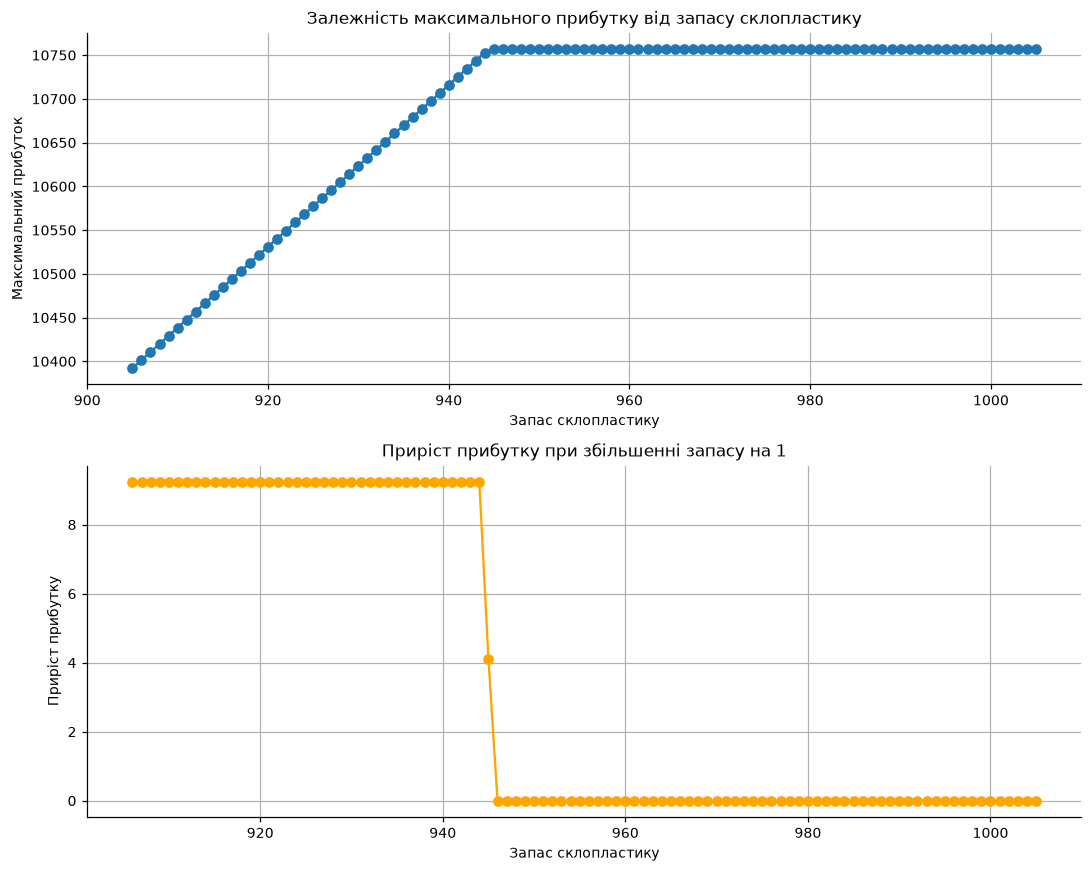

In [8]:
запаси = np.arange(b[0], b[0] + 101, 1)

прибутки = []

без_пребутку = -1
i = 0
for запас in запаси:
    b_copy = b.copy()
    b_copy[0] = запас

    прибутки.append(-linprog(
        c=-c,
        A_ub=A,
        b_ub=b_copy,
        bounds=(0, None)
    ).fun)

    if i > 0 and прибутки[i] == прибутки[i - 1] and без_пребутку == -1:
        без_пребутку = i-1
    i += 1

прибутки = np.array(прибутки)

прирости = np.diff(прибутки)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

print("Остання точка прибутку :", без_пребутку)

# Графік прибутку
ax1.plot(запаси, прибутки, marker='o')
ax1.set_title('Залежність максимального прибутку від запасу склопластику')
ax1.set_xlabel('Запас склопластику')
ax1.set_ylabel('Максимальний прибуток')
ax1.grid(True)

# Графік приросту (нахилу)
ax2.plot(запаси[1:], прирости, marker='o', color='orange')
ax2.set_title('Приріст прибутку при збільшенні запасу на 1')
ax2.set_xlabel('Запас склопластику')
ax2.set_ylabel('Приріст прибутку')
ax2.grid(True)

plt.tight_layout()
plt.show()

**Відповідь 5.2:** *(на скільки одиниць можна збільшити запас, доки тіньова ціна не зміниться;
чи збігається знайдена межа з «допустимим збільшенням» зі звіту Excel)*

Остання точка отримання прибутку спостерігається після додавання 40 одиниць ресурсу, але останній ресурс додається вже з меншим прибутком, після чого прибутковість додавання опускається до нуля. Цей результат повністю співпадає зі звітом: заявлене там максимальне збільшення - 39.445

---
# Етап 6. Рішення про закупівлю

Постачальник пропонує вам додатковий обсяг ресурсу — див. блок «ПРОПОЗИЦІЯ
ПОСТАЧАЛЬНИКА» у ваших даних.
ресурс: Склопластик, м²
ціна:   5.3 за одиницю
обсяг:  до 78 одиниць

### Завдання 6.1
Дайте відповідь директорові на три питання, спираючись на числа, а не на здоровий глузд:

1. **Брати чи не брати?** Порівняйте ціну пропозиції з тіньовою ціною.
2. **Скільки саме брати?** Постачальник пропонує більше, ніж вам потрібно.
3. **Скільки на цьому заробимо?** Порахуйте виграш і перевірте його прямим
   розв'язанням задачі з новим запасом.

In [9]:
b_copy = b.copy()
b_copy[0] += 39

прибуток_плюс_39 = -linprog(
    c=-c,
    A_ub=A,
    b_ub=b_copy,
    bounds=(0, None)
).fun

print("Прибуток при збільшенні запасу склопластику на 39 (з урахуванням ціни ресурсу) :", прибуток_плюс_39 - прибуток - (39 * 5.3))

Прибуток при збільшенні запасу склопластику на 39 (з урахуванням ціни ресурсу) : 154.05000000000183


**Відповідь 6.1:**

* Брати чи ні і чому: треба брати, бо тіньова ціна обіцяє більший приріст (9.25), ніж коштує одиниця ресурсу (5.3).
* Скільки одиниць має сенс купити і чому не більше: має сенс купити 39 одиниць, бо 40-а одиниця та далі дають приріст менший за ціну ресурсу.
* Очікуваний виграш: (9.25 - 5.3) * 39 = 154.05 грошових одиниць.
* Перевірка прямим розв'язанням дала: такий самий результат - 154.05


---
# Етап 7. Перевірка розв'язку

### Завдання 7.1
Порахуйте дві величини:

* скільки виробів мають **ненульовий** випуск;
* скільки обмежень **зв'язні** (ресурс витрачено повністю).

Порівняйте.

In [10]:
ненульових = 2
звязних = 2


In [11]:
assert ненульових is not None and звязних is not None, 'спершу порахуйте'
print('ненульових змінних: %s | зв’язних обмежень: %s' % (ненульових, звязних))
assert ненульових == звязних, ('числа не збіглися — це сигнал. Перевірте розв’язок '
                               'і поясніть причину в клітинці нижче')
print('Етап 7 пройдено')

ненульових змінних: 2 | зв’язних обмежень: 2
Етап 7 пройдено


**Відповідь 7.1:** У результаті розрахунків встановлено, що 2 вироби мають ненульовий випуск, а 2 ресурсні обмеження є зв'язними. Отже, отримані числа збігаються. Це свідчить про те, що кількість виробів, які входять до оптимального виробничого плану, дорівнює кількості ресурсних обмежень, які використовуються повністю. У разі розбіжності це могло б свідчити про особливості структури оптимального плану, зокрема про надлишкові або залежні обмеження, виродженість чи наявність альтернативних оптимальних розв'язків

---
# Етап 8. Цілочисельність

Ваш оптимальний план містить дробові числа. Виготовити 63,3 виробу неможливо.

### Завдання 8.1
Порівняйте три варіанти:

1. розв'язок без умови цілочисельності (уже маєте);
2. **округлений** план — округліть кожне значення до цілого й перевірте, чи він
   узагалі допустимий і скільки прибутку дає;
3. справжній **цілочисельний** оптимум — розв'яжіть задачу з умовою, що всі змінні цілі
   (`cat='Integer'` у PuLP або `integrality=1` у `linprog`).

In [12]:
план_округлений = np.rint(план).astype(int)

# Перевіряємо використання ресурсів
витрати_округлені = A @ план_округлений
допустимий = np.all(витрати_округлені <= b)

прибуток_округлений = c @ план_округлений

# 3. Справжній цілочисельний оптимум
res_int = linprog(
    c=-c,
    A_ub=A,
    b_ub=b,
    bounds=(0, None),
    integrality=np.ones(len(c)),
    method='highs'
)

план_цілий = np.rint(res_int.x).astype(int)
прибуток_цілий = -res_int.fun

# Виведення результатів
print("ПОРІВНЯННЯ ТРЬОХ ВАРІАНТІВ")
print("=" * 65)

print("\n1. Без умови цілочисельності:")
print("План:", план)
print("Прибуток:", прибуток)

print("\n2. Округлений план:")
print("План:", план_округлений)
print("Використання ресурсів:", витрати_округлені)
print("Допустимий:", допустимий)
print("Прибуток:", прибуток_округлений)

print("\n3. Цілочисельний оптимум:")
print("План:", план_цілий)
print("Прибуток:", прибуток_цілий)

print("\nПОРІВНЯННЯ ПРИБУТКУ")
print(f"Дробовий план:       {прибуток:.2f}")
print(f"Округлений план:     {прибуток_округлений:.2f}")
print(f"Цілочисельний план:  {прибуток_цілий:.2f}")

ПОРІВНЯННЯ ТРЬОХ ВАРІАНТІВ

1. Без умови цілочисельності:
План: [  0.           0.         183.25        57.33333333]
Прибуток: 10392.249999999998

2. Округлений план:
План: [  0   0 183  57]
Використання ресурсів: [903. 342. 834. 720. 228.]
Допустимий: True
Прибуток: 10362.0

3. Цілочисельний оптимум:
План: [  0   2 185  55]
Прибуток: 10368.0

ПОРІВНЯННЯ ПРИБУТКУ
Дробовий план:       10392.25
Округлений план:     10362.00
Цілочисельний план:  10368.00


**Відповідь 8.1:**

| Варіант | План                      | Прибуток | Допустимий? |
|---|---------------------------|----------|-------------|
| без умови цілочисельності | [0, 0, 183.25, 57.33333333] | 10392.25 | так         |
| округлений | [0, 0, 183, 57]           | 10362.00 | так         |
| цілочисельний оптимум | [0, 2, 185, 55]           | 10368.00 | так         |

**Висновок:** округлювати не можна, бо цілочисельний оптимальний розв'язок може розподілити остачу ресурсів серед інших виробів, щоб не мати залишків (що ми і бачимо в моєму прикладі)


---
# ЧАСТИНА 2. Транспортна задача

Друга частина виконується самостійно. Тут ви застосуєте ту саму методику до задачі
іншого класу — і побачите, що вона поводиться інакше.

# Етап 9. Ваші дані

### Завдання 9.1
Сформуйте власні дані:

* **три міста-постачальники** — за першими трьома літерами вашого **прізвища**;
* **чотири міста-споживачі** — за першими чотирма літерами вашого **імені**;
* **матриця відстаней 3 × 4** — реальні відстані автошляхами за Google Maps, у кілометрах;
* **запаси і попит** — невеликі цілі числа, підберіть так, щоб **сумарний запас
  дорівнював сумарному попиту**.

> Якщо на якусь літеру міста немає — беріть наступну літеру прізвища чи імені.
> Якщо сумарний запас не дорівнює попиту, задача з обмеженнями-рівностями
> **не матиме розв'язку взагалі**. Це не помилка Python — це властивість моделі.

In [13]:
постачальники = ["Миколаїв", "Умань" , "Рівне"]
споживачі = ["Вишневе", "Львів", "Авдіївка", "Дніпро"]
D = np.array([[477, 807, 564, 320],
              [205, 534, 666, 419],
              [322, 212, 1052,779]])  # матриця відстаней 3 x 4, км
запас = [240, 610, 300]  # 3 числа
попит = [150, 435, 215, 350]  # 4 числа

assert len(постачальники) == 3 and len(споживачі) == 4, 'потрібно 3 постачальники і 4 споживачі'
assert D.shape == (3, 4), 'матриця відстаней має бути 3 x 4'
assert sum(запас) == sum(попит), 'сумарний запас має дорівнювати сумарному попиту'
pd.DataFrame(D, index=постачальники, columns=споживачі)

,Вишневе,Львів,Авдіївка,Дніпро
Миколаїв,477,807,564,320
Умань,205,534,666,419
Рівне,322,212,1052,779


---
# Етап 10. Розв'язання транспортної задачі

### Завдання 10.1
Розв'яжіть задачу **двічі різними засобами**: наприклад `pulp` і
`scipy.optimize.linprog(method='highs')`. Обмеження — рівності.

Для кожного розв'язку виведіть: оптимальний план перевезень, сумарну вартість
і **тіньові ціни всіх обмежень**.

In [14]:
# Кількість постачальників і споживачів
m, n = D.shape

# 1. Створюємо задачу мінімізації
model = pl.LpProblem("Transport_Task", pl.LpMinimize)

# 2. Створюємо змінні
x = {
    (i, j): model.add_variable(
        f"x_{i}_{j}",
        lowBound=0
    )
    for i in range(m)
    for j in range(n)
}

# 3. Цільова функція — мінімізація вартості
model += pl.lpSum(
    D[i, j] * x[i, j]
    for i in range(m)
    for j in range(n)
), "Total_Cost"

# 4. Обмеження за запасами постачальників
for i in range(m):
    model += (
        pl.lpSum(x[i, j] for j in range(n)) == запас[i],
        f"Запас_{i}"
    )

# 5. Обмеження за попитом споживачів
for j in range(n):
    model += (
        pl.lpSum(x[i, j] for i in range(m)) == попит[j],
        f"Попит_{j}"
    )

# 6. Розв'язання через CBC
stats = model.solve(pl.COIN_CMD(msg=False))

# 7. Перевірка результату
print("Статус:", stats.status_str)

if stats.status_str == "Optimal":

    # Оптимальний план
    план_pulp = np.array([
        [pl.value(x[i, j]) for j in range(n)]
        for i in range(m)
    ])

    print("\nОПТИМАЛЬНИЙ ПЛАН ПЕРЕВЕЗЕНЬ")
    print("=" * 60)

    print(pd.DataFrame(
        план_pulp,
        index=постачальники,
        columns=споживачі
    ))

    # Загальна вартість
    вартість_pulp = pl.value(model.objective)

    print("\nМінімальна вартість:", вартість_pulp)

    # 8. Тіньові ціни всіх обмежень
    print("\nТІНЬОВІ ЦІНИ ОБМЕЖЕНЬ")
    print("=" * 60)

    for con in model.constraints():
        print(f"{con.name}: {con.pi:.4f}")

else:
    print("Не вдалося знайти оптимальний розв'язок.")

Статус: Optimal

ОПТИМАЛЬНИЙ ПЛАН ПЕРЕВЕЗЕНЬ
          Вишневе  Львів  Авдіївка  Дніпро
Миколаїв      0.0    0.0     215.0    25.0
Умань       150.0  135.0       0.0   325.0
Рівне         0.0  300.0       0.0     0.0

Мінімальна вартість: 431875.0

ТІНЬОВІ ЦІНИ ОБМЕЖЕНЬ
Запас_0: 106.0000
Запас_1: 205.0000
Запас_2: -117.0000
Попит_0: 0.0000
Попит_1: 329.0000
Попит_2: 458.0000
Попит_3: 214.0000


In [15]:
m, n = D.shape

# Цільова функція
c_transport = D.flatten()

# Матриця обмежень
A_eq = []
b_eq = []

# Обмеження за запасами
for i in range(m):
    row = np.zeros((m, n))
    row[i, :] = 1

    A_eq.append(row.flatten())
    b_eq.append(запас[i])

# Обмеження за попитом
for j in range(n):
    row = np.zeros((m, n))
    row[:, j] = 1

    A_eq.append(row.flatten())
    b_eq.append(попит[j])

A_eq = np.array(A_eq)
b_eq = np.array(b_eq)

# Розв'язання задачі
res_transport = linprog(
    c=c_transport,
    A_eq=A_eq,
    b_eq=b_eq,
    bounds=(0, None),
    method='highs'
)

if res_transport.success:

    план_linprog = res_transport.x.reshape(m, n)

    print("РОЗВ'ЯЗОК LINPROG")
    print("=" * 60)

    print("\nОптимальний план перевезень:")
    print(pd.DataFrame(
        план_linprog,
        index=постачальники,
        columns=споживачі
    ))

    print("\nМінімальна вартість:", res_transport.fun)

    # Тіньові ціни
    print("\nТіньові ціни обмежень:")

    for i in range(m):
        print(
            f"Запас {постачальники[i]}: "
            f"{res_transport.eqlin.marginals[i]:.4f}"
        )

    for j in range(n):
        print(
            f"Попит {споживачі[j]}: "
            f"{res_transport.eqlin.marginals[m+j]:.4f}"
        )

else:
    print("Помилка:", res_transport.message)

РОЗВ'ЯЗОК LINPROG

Оптимальний план перевезень:
          Вишневе  Львів  Авдіївка  Дніпро
Миколаїв      0.0    0.0     215.0    25.0
Умань       150.0  135.0       0.0   325.0
Рівне         0.0  300.0       0.0     0.0

Мінімальна вартість: 431875.0

Тіньові ціни обмежень:
Запас Миколаїв: -0.0000
Запас Умань: 99.0000
Запас Рівне: -223.0000
Попит Вишневе: 106.0000
Попит Львів: 435.0000
Попит Авдіївка: 564.0000
Попит Дніпро: 320.0000


### Завдання 10.2 — головне питання цієї частини
Порівняйте два набори тіньових цін.

**Сумарна вартість у двох розв'язувачів однакова. А тіньові ціни?**

Якщо вони різні — це не помилка. Знайдіть закономірність: подивіться на різницю
між відповідними значеннями окремо для постачальників і окремо для споживачів.

In [16]:
# Тіньові ціни з PuLP
ціни_pulp = np.array([con.pi for con in model.constraints()])

# Тіньові ціни з linprog
ціни_linprog = res_transport.eqlin.marginals

# Формуємо таблицю порівняння
порівняння = pd.DataFrame({
    'Обмеження': (
        [f'Постачальник: {x}' for x in постачальники] +
        [f'Споживач: {x}' for x in споживачі]
    ),
    'PuLP': ціни_pulp,
    'linprog': ціни_linprog,
    'Різниця (PuLP - linprog)': ціни_pulp - ціни_linprog
})

print(порівняння.to_string(index=False))

print("\nРізниця для постачальників:")
print(ціни_pulp[:3] - ціни_linprog[:3])

print("\nРізниця для споживачів:")
print(ціни_pulp[3:] - ціни_linprog[3:])

             Обмеження   PuLP  linprog  Різниця (PuLP - linprog)
Постачальник: Миколаїв  106.0     -0.0                     106.0
   Постачальник: Умань  205.0     99.0                     106.0
   Постачальник: Рівне -117.0   -223.0                     106.0
     Споживач: Вишневе    0.0    106.0                    -106.0
       Споживач: Львів  329.0    435.0                    -106.0
    Споживач: Авдіївка  458.0    564.0                    -106.0
      Споживач: Дніпро  214.0    320.0                    -106.0

Різниця для постачальників:
[106. 106. 106.]

Різниця для споживачів:
[-106. -106. -106. -106.]


**Відповідь 10.2:**

* Вартість у двох розв'язувачів: 431875
* Тіньові ціни збіглися чи ні: ні
* Яку закономірність ви побачили в різниці: різниця тіньових цін однакова між постачальниками, а споживачі мають ту саму різницю з протилежним знаком
* Що це означає для того, хто збирається ухвалювати рішення за цим звітом: для ухвалення рішень слід враховувати оптимальний план, загальну вартість і зміни цільової функції, а не трактувати кожну тіньову ціну ізольовано.


---
# Етап 11. Перевірка розв'язку — і чому вона тут не працює

### Завдання 11.1
Порахуйте для транспортної задачі те саме, що на етапі 7:

* кількість **ненульових перевезень**;
* кількість **зв'язних обмежень**.

Порівняйте з числом `3 + 4 = 7` — кількістю обмежень у задачі.

In [17]:
# Кількість ненульових перевезень
кількість_перевезень = np.sum(план_linprog > 1e-6)

# Кількість зв'язних обмежень
кількість_обмежень = (
    np.sum(np.isclose(план_linprog.sum(axis=1), запас)) +
    np.sum(np.isclose(план_linprog.sum(axis=0), попит))
)

print("Кількість ненульових перевезень:", кількість_перевезень)
print("Кількість зв'язних обмежень:", кількість_обмежень)

Кількість ненульових перевезень: 6
Кількість зв'язних обмежень: 7


**Відповідь 11.1:**

* Ненульових перевезень: 6
* Зв'язних обмежень: 7
* Чому в транспортній задачі зв'язними виявляються **всі** обмеження: тому що в оптимальному плані всі постачальники повністю використали свої запаси, а попит усіх споживачів повністю задоволений.
* На скільки ненульових перевезень менше і чому саме на стільки: ненульових перевезень на одне менше, ніж обмежень. Це нормально для збалансованої транспортної задачі: одне з обмежень є лінійно залежним від інших, тому незалежних обмежень фактично 6.


### Завдання 11.2 — візуалізація
Побудуйте дві теплові карти поруч: матрицю відстаней і матрицю оптимальних перевезень.
Підпишіть осі та значення в комірках.

*За бажанням (не оцінюється): граф маршрутів через `networkx`, де товщина ребра
пропорційна обсягу перевезення.*

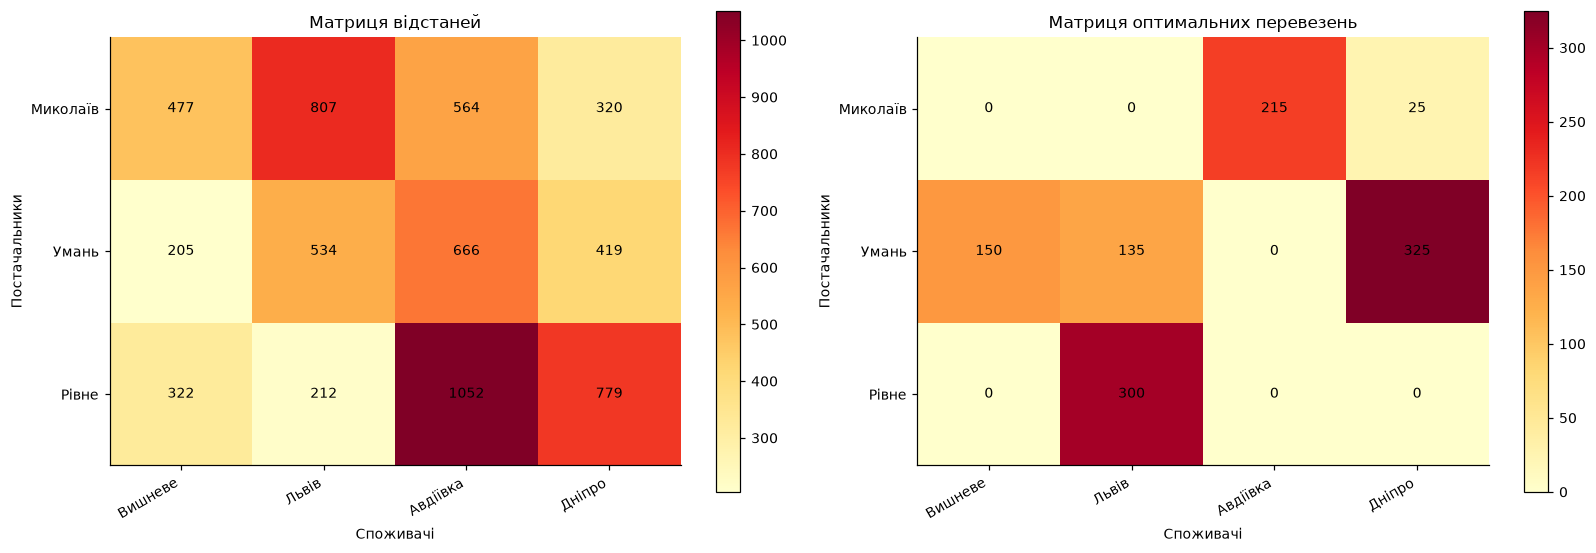

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

матриці = [D, план_linprog]
заголовки = ["Матриця відстаней", "Матриця оптимальних перевезень"]

for ax, матриця, заголовок in zip(axes, матриці, заголовки):
    im = ax.imshow(матриця, cmap="YlOrRd")

    ax.set_title(заголовок)
    ax.set_xticks(range(len(споживачі)))
    ax.set_xticklabels(споживачі, rotation=30, ha="right")
    ax.set_yticks(range(len(постачальники)))
    ax.set_yticklabels(постачальники)

    # Підпис значень у кожній комірці
    for i in range(len(постачальники)):
        for j in range(len(споживачі)):
            ax.text(j, i, f"{матриця[i, j]:.0f}",
                    ha="center", va="center", color="black")

    ax.set_xlabel("Споживачі")
    ax.set_ylabel("Постачальники")
    fig.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()

**Висновок:** на теплових картах можна побачити, що пріорітет доставки віддається маршрутам з меншою відстанню.

---
# Етап 12. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями **дозволено**. Обов'язковою є прозорість.
Порушенням є не використання інструмента, а нездатність пояснити власний код
і власні числа на захисті.

Для кожного етапу оберіть одне: `'ні'`, `'синтаксис'`, `'код, перевірено'`,
`'текст, перероблено'`, `'текст, як є'`.

In [19]:
ІНСТРУМЕНТИ_ШІ = 'ChatGPT'  # напр. 'ChatGPT' або 'не використовував'

ДЕКЛАРАЦІЯ = {
    'етап 1, формалізація моделі': 'ні',
    'етап 2, побудова моделі в Excel': 'ні',
    'етап 3, код на Python': 'синтаксис',
    'етапи 4–5, читання та перевірка звіту': 'код, перевірено',
    'етап 6, рішення про закупівлю': 'ні',
    'етапи 7–8, перевірка та цілочисельність': 'код, перевірено',
    'етапи 9–11, транспортна задача': 'код, перевірено',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно.
ЩО_ПЕРЕВІРЕНО = 'Перевірено коректність отриманих результатів, коректність побудови та підписання графіків, перевірено весь згенерований код.'

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-яке число
# цієї роботи та внести зміни в модель на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True

In [20]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}
assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше (зараз %d символів, '
                                           'потрібно щонайменше 120)' % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'
print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-42s %s' % ('автор:', ПІБ))
print('%-42s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-42s %s' % (k + ':', v))
print('-' * 78)
print(ЩО_ПЕРЕВІРЕНО)

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                     Мурашко Владислав Сергійович
інструменти:                               ChatGPT
------------------------------------------------------------------------------
етап 1, формалізація моделі:               ні
етап 2, побудова моделі в Excel:           ні
етап 3, код на Python:                     синтаксис
етапи 4–5, читання та перевірка звіту:     код, перевірено
етап 6, рішення про закупівлю:             ні
етапи 7–8, перевірка та цілочисельність:   код, перевірено
етапи 9–11, транспортна задача:            код, перевірено
------------------------------------------------------------------------------
Перевірено коректність отриманих результатів, коректність побудови та підписання графіків, перевірено весь згенерований код.


---
# Крок 13. Фінальна самоперевірка

In [21]:
перевірки = {
    'ПІБ і варіант заповнено': bool(ПІБ) and 1 <= ВАРІАНТ <= 30,
    'Excel і Python дали однаковий план': abs(прибуток - EXCEL_ПРИБУТОК) < 0.5,
    'перевірку «ненульові = зв’язні» зроблено': ненульових == звязних,
    'дані транспортної задачі введено': len(постачальники) == 3 and len(споживачі) == 4,
    'баланс запасів і попиту': sum(запас) == sum(попит),
    'декларацію заповнено': bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)
if all(перевірки.values()):
    print('\nТехнічна частина виконана.')
    print('Переконайтеся, що заповнені ВСІ клітинки з відповідями,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     Excel і Python дали однаковий план
OK     перевірку «ненульові = зв’язні» зроблено
OK     дані транспортної задачі введено
OK     баланс запасів і попиту
OK     декларацію заповнено

Технічна частина виконана.
Переконайтеся, що заповнені ВСІ клітинки з відповідями,
і виконайте Kernel → Restart & Run All перед здачею.
